In [1]:
import sys
from pathlib import Path

print("Python:", sys.version)
print("Entorno:", sys.executable)
print("Directorio:", Path.cwd())
print("Notebook configurado correctamente")

Python: 3.11.2 (tags/v3.11.2:878ead1, Feb  7 2023, 16:38:35) [MSC v.1934 64 bit (AMD64)]
Entorno: c:\Users\gabri\Actividad5\.venv\Scripts\python.exe
Directorio: c:\Users\gabri\Actividad5\fuentes
Notebook configurado correctamente


In [2]:
import pandas as pd
from pathlib import Path

# Directorio principal del proyecto
BASE_DIR = Path.cwd().parent

# Cargar datasets
train = pd.read_csv(BASE_DIR / "datos" / "train.csv")
test = pd.read_csv(BASE_DIR / "datos" / "test.csv")

print("DATOS CARGADOS CORRECTAMENTE")
print("---------------------------")
print("Entrenamiento:", train.shape)
print("Prueba:", test.shape)

print("\nDistribución de entrenamiento:")
print(train["clase"].value_counts())

print("\nDistribución de prueba:")
print(test["clase"].value_counts())

print("\nValores nulos:")
print("Entrenamiento:", train.isnull().sum().sum())
print("Prueba:", test.isnull().sum().sum())

DATOS CARGADOS CORRECTAMENTE
---------------------------
Entrenamiento: (3588, 1766)
Prueba: (898, 1766)

Distribución de entrenamiento:
clase
Tomato___Late_blight     1520
Tomato___healthy         1268
Tomato___Early_blight     800
Name: count, dtype: int64

Distribución de prueba:
clase
Tomato___Late_blight     381
Tomato___healthy         317
Tomato___Early_blight    200
Name: count, dtype: int64

Valores nulos:
Entrenamiento: 0
Prueba: 0


In [3]:

# Separar características y etiquetas

columnas_hog = [
    columna for columna in train.columns
    if columna.startswith("hog_")
]

X_train = train[columnas_hog]
y_train = train["clase"]

X_test = test[columnas_hog]
y_test = test["clase"]

print("PREPARACIÓN DE VARIABLES FINALIZADA")
print("----------------------------------")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nClases disponibles:")
print(y_train.unique())


PREPARACIÓN DE VARIABLES FINALIZADA
----------------------------------
X_train: (3588, 1764)
y_train: (3588,)
X_test: (898, 1764)
y_test: (898,)

Clases disponibles:
<ArrowStringArray>
['Tomato___healthy', 'Tomato___Late_blight', 'Tomato___Early_blight']
Length: 3, dtype: str


In [5]:

import joblib
from pathlib import Path

# Directorio principal del proyecto
BASE_DIR = Path.cwd().parent
MODELOS_DIR = BASE_DIR / "modelos"

# Mostrar archivos disponibles
print("MODELOS DISPONIBLES")
print("------------------")

for archivo in MODELOS_DIR.iterdir():
    print(archivo.name)


MODELOS DISPONIBLES
------------------


In [6]:

from pathlib import Path

BASE_DIR = Path.cwd().parent

print("BUSCANDO MODELOS GUARDADOS")
print("-------------------------")

extensiones = (".pkl", ".joblib", ".skops")

archivos = [
    archivo
    for archivo in BASE_DIR.rglob("*")
    if archivo.is_file()
    and archivo.suffix.lower() in extensiones
    and ".venv" not in archivo.parts
    and ".git" not in archivo.parts
]

if archivos:
    for archivo in archivos:
        print(archivo.relative_to(BASE_DIR))
else:
    print("No se encontraron modelos locales.")
    print("Revisaremos los modelos registrados en MLflow.")


BUSCANDO MODELOS GUARDADOS
-------------------------
mlruns\1\models\m-190cafb1a1a3447781027744396bce32\artifacts\model.skops
mlruns\1\models\m-3c4615e005b44132a7de27b91fcf855d\artifacts\model.skops
mlruns\1\models\m-e66f3e9819c5490c9b0074e51041b056\artifacts\model.skops


In [7]:

import mlflow
import mlflow.sklearn
from pathlib import Path

BASE_DIR = Path.cwd().parent

mlflow.set_tracking_uri(
    "sqlite:///" + (BASE_DIR / "mlflow.db").as_posix()
)

print("CARGANDO MODELOS DESDE MLFLOW")
print("--------------------------------")

# Cargar SVM
modelo_svm = mlflow.sklearn.load_model(
    "models:/m-e66f3e9819c5490c9b0074e51041b056"
)

print("SVM:", type(modelo_svm).__name__)

# Cargar Random Forest
modelo_rf = mlflow.sklearn.load_model(
    "models:/m-190cafb1a1a3447781027744396bce32"
)

print("Random Forest:", type(modelo_rf).__name__)

print("\nMODELOS CARGADOS CORRECTAMENTE")


CARGANDO MODELOS DESDE MLFLOW
--------------------------------
SVM: Pipeline
Random Forest: RandomForestClassifier

MODELOS CARGADOS CORRECTAMENTE


In [8]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

resultados = []

modelos = {
    "SVM": modelo_svm,
    "Random Forest": modelo_rf
}

for nombre, modelo in modelos.items():

    # Predicciones
    y_pred = modelo.predict(X_test)
    y_prob = modelo.predict_proba(X_test)

    # Métricas
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, average="macro"
    )
    recall = recall_score(
        y_test, y_pred, average="macro"
    )
    f1 = f1_score(
        y_test, y_pred, average="macro"
    )
    roc_auc = roc_auc_score(
        y_test,
        y_prob,
        multi_class="ovr",
        average="macro",
        labels=modelo.classes_
    )

    resultados.append({
        "Modelo": nombre,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-macro": f1,
        "ROC-AUC": roc_auc
    })

df_resultados = pd.DataFrame(resultados)

print("COMPARACIÓN DE MODELOS")
print("----------------------")
display(df_resultados.round(4))


COMPARACIÓN DE MODELOS
----------------------


,Modelo,Accuracy,Precision,Recall,F1-macro,ROC-AUC
0,SVM,0.8686,0.8525,0.8357,0.8411,0.9653
1,Random Forest,0.8430,0.8324,0.7975,0.8046,0.9489


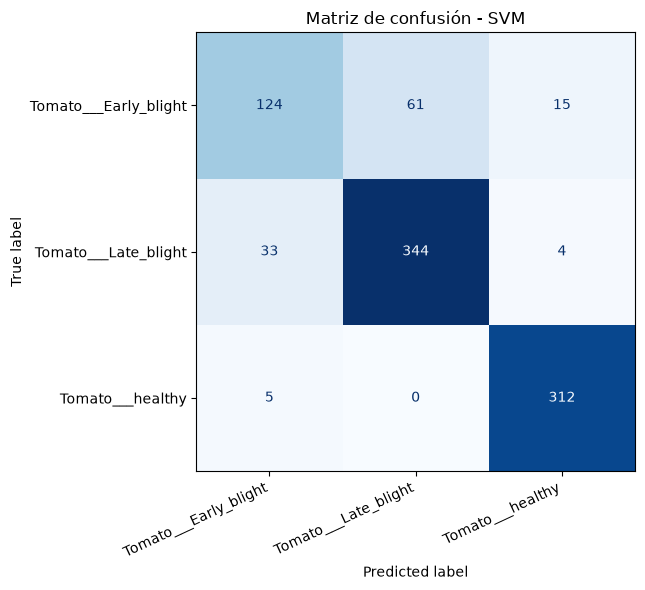

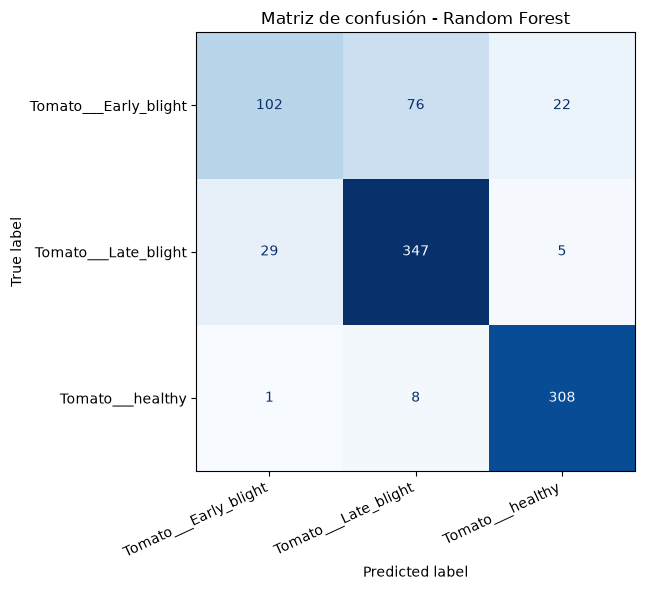

In [9]:

import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Evaluar las predicciones de cada modelo
for nombre, modelo in modelos.items():

    y_pred = modelo.predict(X_test)

    matriz = confusion_matrix(
        y_test,
        y_pred,
        labels=modelo.classes_
    )

    fig, ax = plt.subplots(figsize=(9, 6))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=modelo.classes_
    )

    disp.plot(
        cmap="Blues",
        values_format="d",
        ax=ax,
        colorbar=False
    )

    plt.title(f"Matriz de confusión - {nombre}")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()


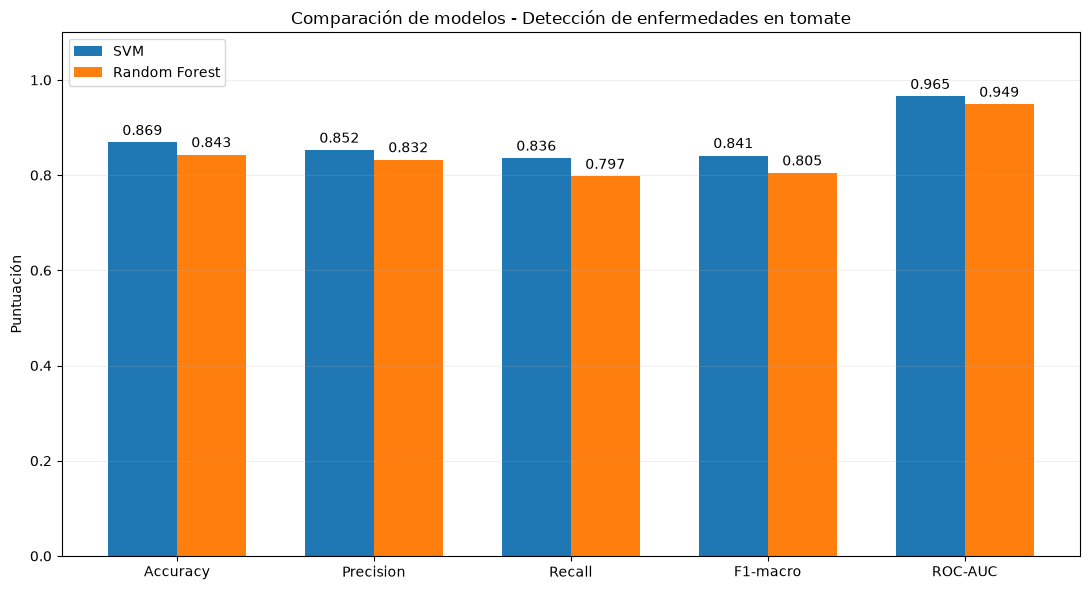

In [10]:

import matplotlib.pyplot as plt
import numpy as np

metricas = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-macro",
    "ROC-AUC"
]

svm = df_resultados.loc[
    df_resultados["Modelo"] == "SVM",
    metricas
].iloc[0].values

rf = df_resultados.loc[
    df_resultados["Modelo"] == "Random Forest",
    metricas
].iloc[0].values

x = np.arange(len(metricas))
ancho = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

barras_svm = ax.bar(
    x - ancho / 2,
    svm,
    ancho,
    label="SVM"
)

barras_rf = ax.bar(
    x + ancho / 2,
    rf,
    ancho,
    label="Random Forest"
)

ax.set_ylabel("Puntuación")
ax.set_title(
    "Comparación de modelos - Detección de enfermedades en tomate"
)
ax.set_xticks(x)
ax.set_xticklabels(metricas)
ax.set_ylim(0, 1.1)
ax.legend()
ax.grid(axis="y", alpha=0.2)

ax.bar_label(barras_svm, fmt="%.3f", padding=3)
ax.bar_label(barras_rf, fmt="%.3f", padding=3)

plt.tight_layout()
plt.show()


### Validación cruzada de los modelos

Se evaluaron los algoritmos Support Vector Machine (SVM) y Random Forest mediante validación cruzada de cinco particiones (*5-fold cross-validation*).

El objetivo fue estimar la capacidad de generalización de los modelos y comprobar la estabilidad de sus resultados sobre diferentes subconjuntos de entrenamiento.

| Modelo | F1-macro promedio | Desviación estándar |
|---|---:|---:|
| SVM | 0.8323 | 0.0214 |
| Random Forest | 0.7910 | 0.0135 |

SVM obtuvo el mejor rendimiento promedio. Random Forest presentó una desviación estándar menor, lo que indica una variación más reducida entre particiones, aunque con un desempeño general inferior.

Estos resultados respaldan la selección de SVM como modelo final, considerando también su rendimiento sobre el conjunto independiente de prueba.

In [11]:

print("HIPERPARÁMETROS DE LOS MODELOS")
print("--------------------------------")

print("\nSVM:")
print(modelo_svm.get_params())

print("\nRandom Forest:")
print(modelo_rf.get_params())


HIPERPARÁMETROS DE LOS MODELOS
--------------------------------

SVM:
{'memory': None, 'steps': [('scaler', StandardScaler()), ('svm', SVC(C=10, probability=True))], 'transform_input': None, 'verbose': False, 'scaler': StandardScaler(), 'svm': SVC(C=10, probability=True), 'scaler__copy': True, 'scaler__with_mean': True, 'scaler__with_std': True, 'svm__C': 10, 'svm__break_ties': False, 'svm__cache_size': 200, 'svm__class_weight': None, 'svm__coef0': 0.0, 'svm__decision_function_shape': 'ovr', 'svm__degree': 3, 'svm__gamma': 'scale', 'svm__kernel': 'rbf', 'svm__max_iter': -1, 'svm__probability': True, 'svm__random_state': None, 'svm__shrinking': True, 'svm__tol': 0.001, 'svm__verbose': False}

Random Forest:
{'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 5, 'min_weight_fraction_leaf': 0.0, 'mono

In [12]:

from pathlib import Path

BASE_DIR = Path.cwd().parent
FUENTES_DIR = BASE_DIR / "fuentes"

print("BÚSQUEDA DE GRID SEARCH EN EL PROYECTO")
print("--------------------------------------")

encontrado = False

for archivo in FUENTES_DIR.glob("*.py"):
    contenido = archivo.read_text(
        encoding="utf-8",
        errors="replace"
    )

    if "GridSearchCV" in contenido or "RandomizedSearchCV" in contenido:
        print(f"Encontrado en: {archivo.name}")
        encontrado = True

if not encontrado:
    print("No se encontró GridSearchCV ni RandomizedSearchCV")
    print("en los archivos Python del proyecto.")


BÚSQUEDA DE GRID SEARCH EN EL PROYECTO
--------------------------------------
Encontrado en: entrenar_rf.py
Encontrado en: entrenar_svm.py


In [13]:

from pathlib import Path

BASE_DIR = Path.cwd().parent
FUENTES_DIR = BASE_DIR / "fuentes"

archivos = [
    "entrenar_svm.py",
    "entrenar_rf.py"
]

for nombre in archivos:
    ruta = FUENTES_DIR / nombre

    print("\n" + "=" * 60)
    print("ARCHIVO:", nombre)
    print("=" * 60)

    if ruta.exists():
        contenido = ruta.read_text(
            encoding="utf-8",
            errors="replace"
        )
        print(contenido)
    else:
        print("Archivo no encontrado")



ARCHIVO: entrenar_svm.py

from pathlib import Path
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold
)

BASE_DIR = Path(__file__).resolve().parent.parent
ARCHIVO = BASE_DIR / "datos" / "train.csv"

RANDOM_STATE = 42

def entrenar_svm():

    print("ACTIVIDAD 5 - ENTRENAMIENTO SVM")
    print("--------------------------------")

    df = pd.read_csv(ARCHIVO)

    X = df.drop(columns=["archivo", "clase"])
    y = df["clase"]

    # Pipeline para evitar fuga de datos
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC())
    ])

    # Hiperparametros
    parametros = {
        "svm__C": [0.1, 1, 10],
        "svm__kernel": ["linear", "rbf"],
        "svm__gamma": ["scale"]
    }

    # Validacion cruzada estratificada
    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        rand

In [14]:

import pandas as pd
from pathlib import Path

BASE_DIR = Path.cwd().parent
EVIDENCIAS = BASE_DIR / "evidencias"

archivos = {
    "SVM": "resultados_svm.csv",
    "Random Forest": "resultados_rf.csv"
}

for nombre, archivo in archivos.items():

    ruta = EVIDENCIAS / archivo

    print("\n" + "=" * 55)
    print("RESULTADOS GRID SEARCH:", nombre)
    print("=" * 55)

    if not ruta.exists():
        print("No se encontró:", archivo)
        continue

    df_grid = pd.read_csv(ruta)

    print("Combinaciones evaluadas:", len(df_grid))

    if "mean_test_score" not in df_grid.columns:
        print("No se encontró la columna de puntuaciones.")
        continue

    mejor = df_grid.sort_values(
        "mean_test_score",
        ascending=False
    ).iloc[0]

    print("\nMejor F1-macro CV:",
          round(mejor["mean_test_score"], 4))

    print("Desviación estándar:",
          round(mejor["std_test_score"], 4))

    print("\nMejores hiperparámetros:")

    for columna in df_grid.columns:
        if columna.startswith("param_"):
            print(
                columna.replace("param_", ""),
                ":",
                mejor[columna]
            )



RESULTADOS GRID SEARCH: SVM
Combinaciones evaluadas: 6

Mejor F1-macro CV: 0.8323
Desviación estándar: 0.0214

Mejores hiperparámetros:
svm__C : 10.0
svm__gamma : scale
svm__kernel : rbf

RESULTADOS GRID SEARCH: Random Forest
Combinaciones evaluadas: 8

Mejor F1-macro CV: 0.791
Desviación estándar: 0.0135

Mejores hiperparámetros:
max_depth : nan
min_samples_split : 5
n_estimators : 200


In [15]:

import pandas as pd

resumen_grid = []

archivos_grid = {
    "SVM": "resultados_svm.csv",
    "Random Forest": "resultados_rf.csv"
}

for nombre, archivo in archivos_grid.items():

    ruta = BASE_DIR / "evidencias" / archivo
    df = pd.read_csv(ruta)

    mejor = df.loc[df["mean_test_score"].idxmax()]

    resumen_grid.append({
        "Modelo": nombre,
        "Combinaciones": len(df),
        "F1-macro CV": mejor["mean_test_score"],
        "Desviación estándar": mejor["std_test_score"],
        "Mejores parámetros": str(mejor["params"])
    })

df_grid_resumen = pd.DataFrame(resumen_grid)

print("RESUMEN DE OPTIMIZACIÓN DE HIPERPARÁMETROS")
print("-----------------------------------------")

display(df_grid_resumen)


RESUMEN DE OPTIMIZACIÓN DE HIPERPARÁMETROS
-----------------------------------------


,Modelo,Combinaciones,F1-macro CV,Desviación estándar,Mejores parámetros
0,SVM,6,0.832349,0.021448,"{'svm__C': 10, 'svm__gamma': 'scale', 'svm__ke..."
1,Random Forest,8,0.790998,0.013532,"{'max_depth': None, 'min_samples_split': 5, 'n..."


### Optimización de hiperparámetros mediante Grid Search

Para optimizar los algoritmos SVM y Random Forest se utilizó `GridSearchCV` de Scikit-learn, con validación cruzada estratificada de cinco particiones (`StratifiedKFold`).

Se seleccionó `f1_macro` como métrica de optimización para considerar el rendimiento de las tres clases de enfermedades de manera equilibrada.

**SVM:** Se evaluaron seis combinaciones de hiperparámetros, variando el parámetro de regularización C y el tipo de kernel. La mejor configuración fue C=10, kernel RBF y gamma=scale, con un F1-macro promedio de 0.8323.

**Random Forest:** Se evaluaron ocho combinaciones, modificando el número de árboles, la profundidad máxima y el número mínimo de muestras para dividir un nodo. La mejor configuración utilizó 200 árboles, profundidad máxima sin límite y min_samples_split=5, con un F1-macro promedio de 0.7910.

Los resultados muestran que SVM obtuvo el mejor desempeño durante la validación cruzada. Esta conclusión también fue respaldada por la evaluación posterior sobre el conjunto independiente de prueba.

La optimización se realizó utilizando únicamente los datos de entrenamiento, evitando utilizar el conjunto de prueba durante la selección de hiperparámetros.

In [16]:

import mlflow
import pandas as pd
from pathlib import Path

BASE_DIR = Path.cwd().parent

mlflow.set_tracking_uri(
    "sqlite:///" + (BASE_DIR / "mlflow.db").as_posix()
)

print("VERIFICACIÓN DE EXPERIMENTOS MLFLOW")
print("----------------------------------")

experimentos = mlflow.search_experiments()

for experimento in experimentos:
    print(
        f"\nExperimento: {experimento.name}"
    )
    print("ID:", experimento.experiment_id)

    ejecuciones = mlflow.search_runs(
        experiment_ids=[experimento.experiment_id]
    )

    print("Ejecuciones registradas:", len(ejecuciones))

    if not ejecuciones.empty:
        columnas = [
            "run_id",
            "status"
        ]

        columnas += [
            c for c in ejecuciones.columns
            if c.startswith("metrics.")
        ]

        display(
            ejecuciones[columnas].head(10)
        )


VERIFICACIÓN DE EXPERIMENTOS MLFLOW
----------------------------------

Experimento: Actividad5_Deteccion_Enfermedades_Tomate
ID: 1
Ejecuciones registradas: 4


,run_id,status,metrics.f1_macro_cv,metrics.test_accuracy,metrics.test_f1_macro,metrics.test_roc_auc_ovr_macro,metrics.test_precision_macro,metrics.test_recall_macro,metrics.f1_macro_std
0,447ceaa6289c475e8b215578e295000a,FINISHED,0.790998,0.842984,0.804641,0.948862,0.832412,0.797457,0.013532
1,5c9150263ada494d8c89e1c4d5abc354,FINISHED,0.832349,0.868597,0.841121,0.965302,0.852471,0.835705,0.021448
2,4623d1797ad240b695ed478243fa820b,FAILED,0.790998,NaN,NaN,NaN,NaN,NaN,0.013532
3,d40372e217c74e0fb77ff20375c4bbb4,FINISHED,0.832349,NaN,NaN,NaN,NaN,NaN,0.021448



Experimento: Default
ID: 0
Ejecuciones registradas: 0


In [17]:

import mlflow

runs = {
    "SVM": "5c9150263ada494d8c89e1c4d5abc354",
    "Random Forest": "447ceaa6289c475e8b215578e295000a"
}

cliente = mlflow.tracking.MlflowClient()

for nombre, run_id in runs.items():

    print("\n" + "=" * 55)
    print("MODELO:", nombre)
    print("=" * 55)

    run = cliente.get_run(run_id)

    print("\nESTADO:")
    print(run.info.status)

    print("\nPARÁMETROS:")
    for clave, valor in run.data.params.items():
        print(f"{clave}: {valor}")

    print("\nMÉTRICAS:")
    for clave, valor in run.data.metrics.items():
        print(f"{clave}: {valor:.4f}")

    print("\nARTEFACTOS:")
    artefactos = cliente.list_artifacts(run_id)

    if artefactos:
        for artefacto in artefactos:
            print(artefacto.path)
    else:
        print("Sin artefactos en la raíz de la ejecución")



MODELO: SVM

ESTADO:
FINISHED

PARÁMETROS:
modelo: SVM
dataset: PlantVillage
caracteristicas: HOG
random_state: 42
cv_folds: 5
memory: None
steps: [('scaler', StandardScaler()), ('svm', SVC(C=10, probability=True))]
transform_input: None
verbose: False
scaler: StandardScaler()
svm: SVC(C=10, probability=True)

MÉTRICAS:
f1_macro_cv: 0.8323
f1_macro_std: 0.0214
test_accuracy: 0.8686
test_precision_macro: 0.8525
test_recall_macro: 0.8357
test_f1_macro: 0.8411
test_roc_auc_ovr_macro: 0.9653

ARTEFACTOS:
evaluacion

MODELO: Random Forest

ESTADO:
FINISHED

PARÁMETROS:
modelo: Random_Forest
dataset: PlantVillage
caracteristicas: HOG
random_state: 42
cv_folds: 5
bootstrap: True
ccp_alpha: 0.0
class_weight: None
criterion: gini
max_depth: None
max_features: sqrt
max_leaf_nodes: None
max_samples: None
min_impurity_decrease: 0.0
min_samples_leaf: 1
min_samples_split: 5
min_weight_fraction_leaf: 0.0
monotonic_cst: None
n_estimators: 200
n_jobs: 1
oob_score: False
verbose: 0
warm_start: False

M

In [18]:

from mlflow.tracking import MlflowClient

cliente = MlflowClient()

runs = {
    "SVM": "5c9150263ada494d8c89e1c4d5abc354",
    "Random Forest": "447ceaa6289c475e8b215578e295000a"
}

for nombre, run_id in runs.items():
    run = cliente.get_run(run_id)

    print("\n" + "=" * 45)
    print(nombre)
    print("=" * 45)

    print("Estado:", run.info.status)
    print("Accuracy:", run.data.metrics.get("test_accuracy"))
    print("F1-macro:", run.data.metrics.get("test_f1_macro"))
    print(
        "ROC-AUC:",
        run.data.metrics.get("test_roc_auc_ovr_macro")
    )

    print("\nArchivos de evaluación:")
    archivos = cliente.list_artifacts(
        run_id,
        path="evaluacion"
    )

    if archivos:
        for archivo in archivos:
            print("-", archivo.path)
    else:
        print("No se encontraron archivos.")



SVM
Estado: FINISHED
Accuracy: 0.8685968819599109
F1-macro: 0.8411213006829669
ROC-AUC: 0.9653017855644853

Archivos de evaluación:
- evaluacion/matriz_SVM.png

Random Forest
Estado: FINISHED
Accuracy: 0.8429844097995546
F1-macro: 0.8046409701181952
ROC-AUC: 0.9488618962078649

Archivos de evaluación:
- evaluacion/matriz_Random_Forest.png


In [19]:

import hashlib
import pandas as pd
from pathlib import Path

BASE_DIR = Path.cwd().parent
DATOS_DIR = BASE_DIR / "datos"

def calcular_sha256(ruta):
    sha256 = hashlib.sha256()

    with open(ruta, "rb") as archivo:
        for bloque in iter(
            lambda: archivo.read(1024 * 1024),
            b""
        ):
            sha256.update(bloque)

    return sha256.hexdigest()

archivos = {
    "Entrenamiento": DATOS_DIR / "train.csv",
    "Prueba": DATOS_DIR / "test.csv"
}

versiones = []

for nombre, ruta in archivos.items():

    if not ruta.exists():
        print("No encontrado:", ruta)
        continue

    df = pd.read_csv(ruta)

    versiones.append({
        "Conjunto": nombre,
        "Archivo": ruta.name,
        "Registros": len(df),
        "Columnas": len(df.columns),
        "SHA256": calcular_sha256(ruta)
    })

df_versiones = pd.DataFrame(versiones)

print("IDENTIFICACIÓN DE VERSIONES DEL DATASET")
print("---------------------------------------")

display(df_versiones)


IDENTIFICACIÓN DE VERSIONES DEL DATASET
---------------------------------------


,Conjunto,Archivo,Registros,Columnas,SHA256
0,Entrenamiento,train.csv,3588,1766,5d6c812849dc74e26ade8507dd262f23b15014260b00ab...
1,Prueba,test.csv,898,1766,deec4e79b2c757054229ebf5bc33e9388d258ca7fdab95...


In [21]:

from datetime import datetime
from pathlib import Path

BASE_DIR = Path.cwd().parent
SALIDA = BASE_DIR / "datos" / "versiones_dataset.csv"

# Registrar la versión del conjunto de datos
df_versiones["Version"] = "1.0"
df_versiones["Fecha_registro"] = datetime.now().strftime(
    "%Y-%m-%d %H:%M:%S"
)
df_versiones["Descripcion"] = (
    "PlantVillage - Características HOG - "
    "Clasificación de enfermedades en tomate"
)

# Guardar el registro
df_versiones.to_csv(
    SALIDA,
    index=False,
    encoding="utf-8-sig"
)

print("REGISTRO DE VERSIONES GENERADO")
print("--------------------------------")
print("Archivo:", SALIDA)
print("Registros:", len(df_versiones))

display(df_versiones[
    ["Conjunto", "Archivo", "Version", "Fecha_registro"]
])


REGISTRO DE VERSIONES GENERADO
--------------------------------
Archivo: c:\Users\gabri\Actividad5\datos\versiones_dataset.csv
Registros: 2


,Conjunto,Archivo,Version,Fecha_registro
0,Entrenamiento,train.csv,1.0,2026-10-18 17:08:02
1,Prueba,test.csv,1.0,2026-10-18 17:08:02
